In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import statsmodels.api as sm 

In [4]:
df = pd.read_csv('ADVERTISING1.csv')
print('=== DATASET OVERVIEW ===')
print(f'Raw Shape: {df.shape}')
print(f'Missing Values: {df.isnull().sum().sum()}')
print(f'Duplicate Rows: {df.duplicated().sum()}')

# Drop redundant CSV index column 'Unnamed: 0'
df_clean = df.drop(columns=['Unnamed: 0']).copy()
print('\n=== SUMMARY STATISTICS ===')
print(df_clean.describe().round(2))

=== DATASET OVERVIEW ===
Raw Shape: (200, 5)
Missing Values: 0
Duplicate Rows: 0

=== SUMMARY STATISTICS ===
           TV   Radio  Newspaper   Sales
count  200.00  200.00     200.00  200.00
mean   147.04   23.26      30.55   14.02
std     85.85   14.85      21.78    5.22
min      0.70    0.00       0.30    1.60
25%     74.38    9.98      12.75   10.38
50%    149.75   22.90      25.75   12.90
75%    218.82   36.52      45.10   17.40
max    296.40   49.60     114.00   27.00


In [5]:
# 2. CORRELATION & STATISTICAL INFERENCE (OLS)
print('\n=== CORRELATION MATRIX ===')
print(df_clean.corr().round(4))

# Fit OLS model to inspect p-values and statistical significance of each channel
X_ols = sm.add_constant(df_clean[['TV', 'Radio', 'Newspaper']])
ols_model = sm.OLS(df_clean['Sales'], X_ols).fit()
print('\n=== OLS REGRESSION STATISTICAL SUMMARY ===')
print(ols_model.summary())


=== CORRELATION MATRIX ===
               TV   Radio  Newspaper   Sales
TV         1.0000  0.0548     0.0566  0.7822
Radio      0.0548  1.0000     0.3541  0.5762
Newspaper  0.0566  0.3541     1.0000  0.2283
Sales      0.7822  0.5762     0.2283  1.0000

=== OLS REGRESSION STATISTICAL SUMMARY ===
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        15:46:37   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                  

In [7]:
# 3. TRAIN-TEST SPLIT & FEATURE ENGINEERING
X = df_clean[['TV', 'Radio', 'Newspaper']]
y = df_clean['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Model A: Standard Additive Multiple Linear Regression
lr_additive = LinearRegression()
lr_additive.fit(X_train, y_train)
y_pred_add = lr_additive.predict(X_test)

# Model B: Synergy / Interaction Linear Regression (TV * Radio)
X_train_inter = X_train.copy()
X_train_inter['TV_x_Radio'] = X_train_inter['TV'] * X_train_inter['Radio']

X_test_inter = X_test.copy()
X_test_inter['TV_x_Radio'] = X_test_inter['TV'] * X_test_inter['Radio']

lr_interaction = LinearRegression()
lr_interaction.fit(X_train_inter, y_train)
y_pred_inter = lr_interaction.predict(X_test_inter)

# Model C: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [8]:
# 4. MODEL EVALUATION ON UNSEEN TEST SET (n=40)
print('\n=== TEST SET PERFORMANCE COMPARISON (n=40) ===')
results = [
    ('Additive Linear Regression', y_pred_add),
    ('Interaction Linear (TV x Radio)', y_pred_inter),
    ('Random Forest Regressor', y_pred_rf),
]

for name, preds in results:
  r2 = r2_score(y_test, preds)
  mae = mean_absolute_error(y_test, preds)
  rmse = np.sqrt(mean_squared_error(y_test, preds))
  print(
      f'{name:32s} | R2: {r2:.4f} | MAE: {mae:.3f}k | RMSE: {rmse:.3f}k units'
  )



=== TEST SET PERFORMANCE COMPARISON (n=40) ===
Additive Linear Regression       | R2: 0.8994 | MAE: 1.461k | RMSE: 1.782k units
Interaction Linear (TV x Radio)  | R2: 0.9742 | MAE: 0.672k | RMSE: 0.902k units
Random Forest Regressor          | R2: 0.9818 | MAE: 0.629k | RMSE: 0.758k units


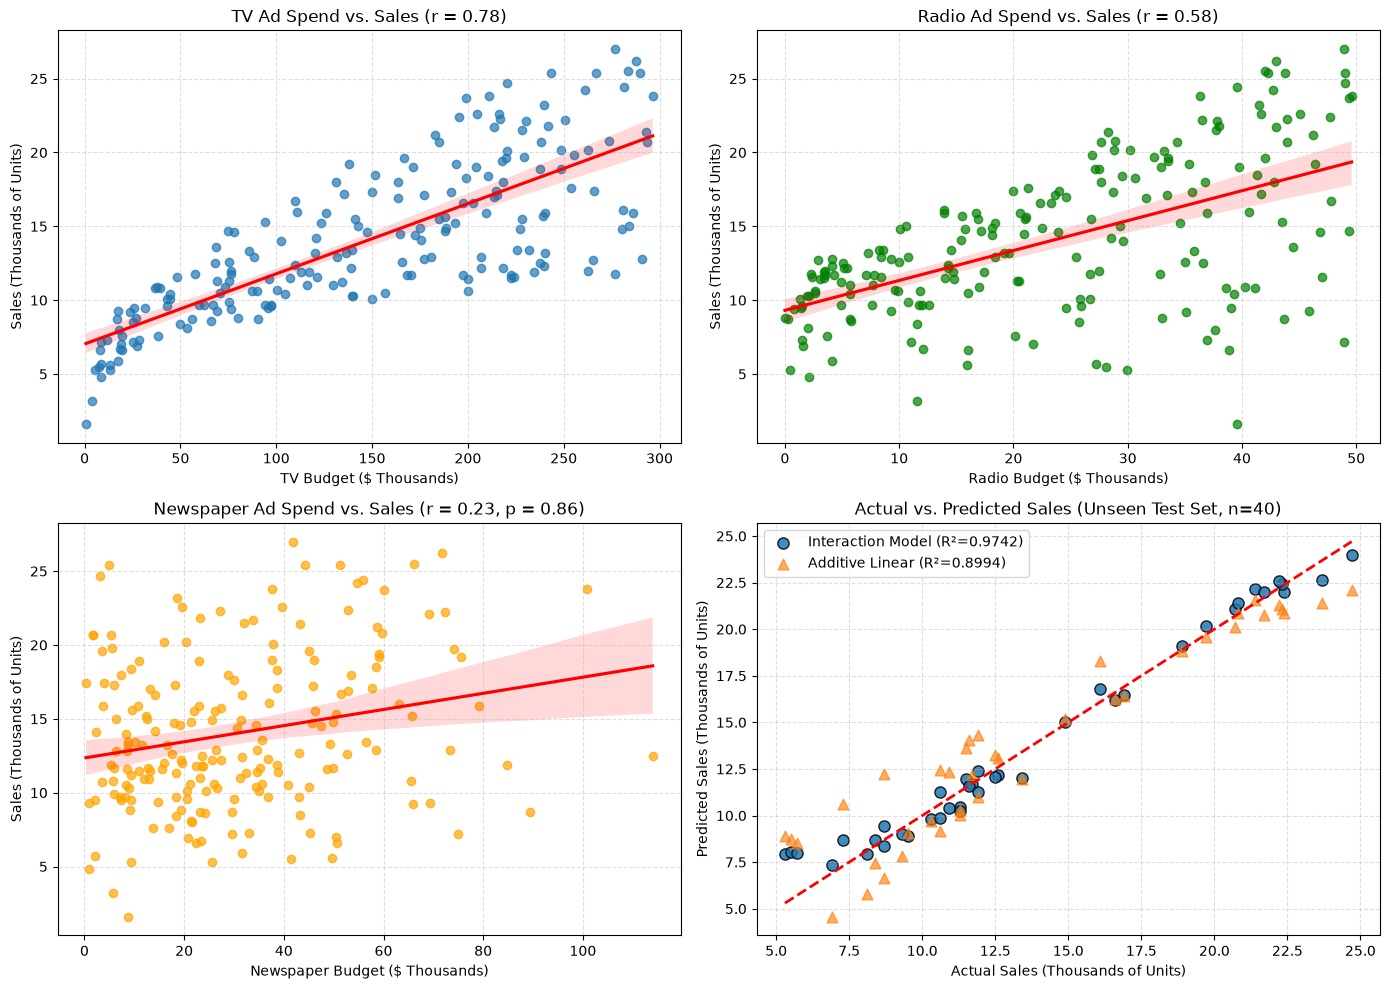

In [9]:
# ==========================================
# 5. VISUALIZATIONS (4-PANEL MARKETING MIX DASHBOARD)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: TV Spend vs Sales
sns.regplot(
    data=df_clean,
    x='TV',
    y='Sales',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'},
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    f"TV Ad Spend vs. Sales (r = {df_clean['TV'].corr(df_clean['Sales']):.2f})"
)
axes[0, 0].set_xlabel('TV Budget ($ Thousands)')
axes[0, 0].set_ylabel('Sales (Thousands of Units)')
axes[0, 0].grid(True, linestyle='--', alpha=0.4)

# Panel 2: Radio Spend vs Sales
sns.regplot(
    data=df_clean,
    x='Radio',
    y='Sales',
    scatter_kws={'alpha': 0.7, 'color': 'green'},
    line_kws={'color': 'red'},
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    f"Radio Ad Spend vs. Sales (r = {df_clean['Radio'].corr(df_clean['Sales']):.2f})"
)
axes[0, 1].set_xlabel('Radio Budget ($ Thousands)')
axes[0, 1].set_ylabel('Sales (Thousands of Units)')
axes[0, 1].grid(True, linestyle='--', alpha=0.4)

# Panel 3: Newspaper Spend vs Sales
sns.regplot(
    data=df_clean,
    x='Newspaper',
    y='Sales',
    scatter_kws={'alpha': 0.7, 'color': 'orange'},
    line_kws={'color': 'red'},
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    f"Newspaper Ad Spend vs. Sales (r = {df_clean['Newspaper'].corr(df_clean['Sales']):.2f}, p = 0.86)"
)
axes[1, 0].set_xlabel('Newspaper Budget ($ Thousands)')
axes[1, 0].set_ylabel('Sales (Thousands of Units)')
axes[1, 0].grid(True, linestyle='--', alpha=0.4)

# Panel 4: Actual vs Predicted (Interaction Model vs Additive)
axes[1, 1].scatter(
    y_test,
    y_pred_inter,
    color='#1f77b4',
    alpha=0.85,
    edgecolors='k',
    s=65,
    label=f'Interaction Model (R²={r2_score(y_test, y_pred_inter):.4f})',
)
axes[1, 1].scatter(
    y_test,
    y_pred_add,
    color='#ff7f0e',
    alpha=0.65,
    marker='^',
    s=60,
    label=f'Additive Linear (R²={r2_score(y_test, y_pred_add):.4f})',
)
axes[1, 1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
)
axes[1, 1].set_title('Actual vs. Predicted Sales (Unseen Test Set, n=40)')
axes[1, 1].set_xlabel('Actual Sales (Thousands of Units)')
axes[1, 1].set_ylabel('Predicted Sales (Thousands of Units)')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()